<div align="center">
    <span style="font-size:30px">
        <strong>
            <!-- Símbolo de Python -->
            <img
                src="https://cdn3.emoji.gg/emojis/1887_python.png"
                style="margin-bottom:-5px"
                width="30px" 
                height="30px"
            >
            <!-- Título -->
            Python para Geólogos
            <!-- Versión -->
            <img 
                src="https://img.shields.io/github/release/kevinalexandr19/manual-python-geologia.svg?style=flat&label=&color=blue"
                style="margin-bottom:-2px" 
                width="40px"
            >
        </strong>
    </span>
    <br>
    <span>
        <!-- Github del proyecto -->
        <a href="https://github.com/kevinalexandr19/manual-python-geologia" target="_blank">
            <img src="https://img.shields.io/github/stars/kevinalexandr19/manual-python-geologia.svg?style=social&label=Github Repo">
        </a>
        &nbsp;&nbsp;
        <!-- Licencia -->
        <img src="https://img.shields.io/github/license/kevinalexandr19/manual-python-geologia.svg?color=forestgreen">
        &nbsp;&nbsp;
        <!-- Release date -->
        <img src="https://img.shields.io/github/release-date/kevinalexandr19/manual-python-geologia?color=gold">
    </span>
    <br>
    <span>
        <!-- Perfil de LinkedIn -->
        <a target="_blank" href="https://www.linkedin.com/in/kevin-alexander-gomez/">
            <img src="https://img.shields.io/badge/-Kevin Alexander Gomez-5eba00?style=social&logo=linkedin">
        </a>
        &nbsp;&nbsp;
        <!-- Perfil de Github -->
        <a target="_blank" href="https://github.com/kevinalexandr19">
            <img src="https://img.shields.io/github/followers/kevinalexandr19.svg?style=social&label=kevinalexandr19&maxAge=2592000">
        </a>
    </span>
    <br>
</div>

***

<span style="color:lightgreen; font-size:25px">**PG306 - Geología estructural y Geomecánica** </span>

Bienvenido al curso!!!

Vamos a revisar aplicaciones de <span style="color:gold">geología estructural</span> usando código en Python. <br>
Es necesario que tengas un conocimiento previo en programación con Python, geología general y geomecánica.


<span style="color:gold; font-size:20px">**Estimación de la probabilidad de fallo en un talud** </span>

***
- [Predicción de la probabilidad de deslizamiento](#parte1)
- [Modelo de estabilidad de talud infinito](#parte2)
- [Simulación de Montecarlo para el análisis de incertidumbre](#parte3)

***

<a id="parte1"></a>

### <span style="color:lightgreen">**Predicción de la probabilidad de deslizamiento**</span>
***

Uno de los peligros geológicos más frecuentes en zonas montañosas o accidentadas es el <span style="color:gold">deslizamiento de taludes naturales</span>.

Estos deslizamientos pueden conducir al colapso de terraplenes arrastrando viviendas y vehículos, también pueden provocar la ruptura de diques y generar inundaciones.

Para taludes naturales con un suelo delgado y superficial, el factor de estabilidad del talud es (según [Skempton y DeLory, 1957](https://www.issmge.org/uploads/publications/1/41/1957_02_0074.pdf)): 

<br>


$$
\Large F = \frac{c}{\gamma z \sin(\alpha) \cos(\alpha)} + \frac{\tan(\phi)}{\tan(\alpha)} - m \frac{\gamma_w \tan(\phi)}{\gamma \tan(\alpha)}
$$



Donde:

- $c$ es la cohesión del suelo
- $\phi$ es el ángulo de fricción interna del suelo
- $\gamma$ es el peso específico del suelo
- $\gamma_w$ es el peso específico del agua
- $\alpha$ es la inclinación del talud con respecto a la horizontal, mayor a 0
- $z$ es la profundidad de la superficie de deslizamiento
- $z_w$ es la altura del nivel freático por encima de la superficie de deslizamiento
- $m$ es el grado de saturación del suelo, donde $m = z_w/z$ <br>
  Cuando $m = 1$, la profundidad del nivel freático ha alcanzado la superficie.

Esta ecuación, conocida como el <span style="color:gold">modelo de estabilidad de talud infinito</span>, analiza un bloque superficial con un determinado espesor y una altura de nivel freático, y supone una falla paralela a la superficie del terreno.



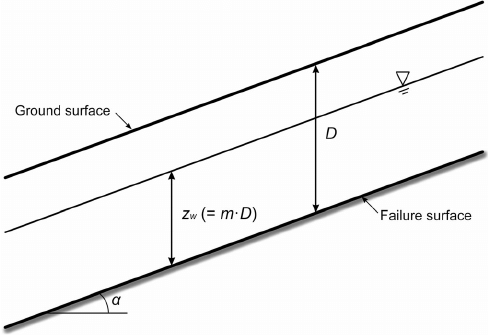



<br>
El criterio de falla ocurre cuando <span style="color:lightgreen">$F < 1$</span>. <br>
Para <span style="color:lightgreen">$1 < F < 1.25$</span> el talud es moderadamente susceptible. <br>
Para <span style="color:lightgreen">$1.25 < F < 1.5$</span> el talud es ligeramente susceptible. <br>
Por último, para <span style="color:lightgreen">$F > 1.5$</span> el talud se considera no susceptible o estable.

***

<a id="parte2"></a>

### <span style="color:lightgreen">**Modelo de estabilidad de talud infinito**</span>
***

In [ ]:
from typing import NamedTuple

import numpy as np
import matplotlib.pyplot as plt
plt.style.use("bmh")

import scipy.stats as stats

Ahora, crearemos una tupla nombrada (`NamedTuple`) que contenga unos parámetros iniciales del modelo de estabilidad:

In [ ]:
# Crear un objeto que contenga los parámetros base del modelo
class Params(NamedTuple):
    z: float = 5                    # Profundidad de la superficie de deslizamiento
    z_w: float = 2.5                # Altura del nivel freático
    m: float = 0.5                  # Grado de saturación del suelo
    c: float = 25                   # Cohesión del suelo
    phi: float = np.radians(30)     # Ángulo de fricción interna
    alpha: float = np.radians(35)   # Ángulo de inclinación del talud
    gamma: float = 20               # Peso específico del suelo
    gamma_w: float = 9.81           # Peso específico del agua

In [ ]:
# Crear una función que represente el modelo de estabilidad en Python
def slope_stability(p: Params):
    c1 = p.c / (p.gamma * p.z * np.sin(p.alpha) * np.cos(p.alpha))
    c2 = np.tan(p.phi) / np.tan(p.alpha)
    c3 = p.m * p.gamma_w * np.tan(p.phi) / (p.gamma * np.tan(p.alpha))
    return c1 + c2 - c3

In [ ]:
slope_stability(Params())

Usando los parámetros iniciales, obtenemos un valor de <span style="color:lightgreen">$F = 1.15$</span>.\
Esto significa que el talud es moderadamente susceptible.

Ahora, analizaremos este modelo de estabilidad de una manera intuitiva.\
Para esto, usaremos los parámetros de inclinación ($\alpha$) y grado de saturación del suelo ($m$).\
Vamos a verificar que la probabilidad de fallo aumenta ($F$ disminuye) cuando alguno de estos dos parámetros aumenta su valor. Los demás valores iniciales permanecerán igual.

***
<span style="color:gold">**Ángulo de inclinación ($\alpha$)**</span>

Crearemos una función que remplace el valor de inclinación dentro del conjunto de parámetros iniciales:

In [ ]:
def slope_stability_alpha(alpha):
    params = Params(alpha=np.radians(alpha))
    return slope_stability(params)

Estableceremos el rango de valores a evaluar y lo asignaremos a `support`, el resultado de la evaluación será asignado a `output`:

In [ ]:
support = np.linspace(1, 45, 100)
output = np.array([slope_stability_alpha(a) for a in support])

Graficamos los resultados:

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5))

ax.plot(support, output, label="$F$")
ax.axhline(y=1, color="r", label=r"$F=1$")

ax.set_xlabel(r"Inclinación del talud ($\alpha$)")
ax.set_ylabel(r"Factor de estabilidad del talud ($F$)")

ax.legend(prop={"size": 16})

plt.show()

***
<span style="color:gold">**Grado de saturación del suelo ($m$)**</span>

Crearemos una función que remplace el valor de inclinación dentro del conjunto de parámetros iniciales:

In [ ]:
def slope_stability_m(m):
    params = Params(m=m)
    return slope_stability(params)

Estableceremos el rango de valores a evaluar y lo asignaremos a `support`, el resultado de la evaluación será asignado a `output`:

In [ ]:
support = np.linspace(0.05, 0.95, 100)
outputs = np.array([slope_stability_m(m) for m in support])

Graficamos los resultados:

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5))

ax.plot(support, outputs, label="$F$")
ax.axhline(y=1, color="r", label="$F=1$")

ax.set_xlabel(r"Grado de saturación del suelo ($m$)")
ax.set_ylabel(r"Factor de estabilidad del talud ($F$)")

ax.legend(prop={"size": 16})

plt.show()

***

<a id="parte3"></a>

### <span style="color:lightgreen">**Simulación de Montecarlo para el análisis de incertidumbre**</span>
***

Los parámetros principales a analizar son la <span style="color:lightgreen">cohesión</span> ($c$) y el <span style="color:lightgreen">ángulo de fricción interna</span> ($\phi$) del suelo, con coeficientes de variación de 0.20 y 0.25 respectivamente. Asumiremos que estas variables $c$ y $\phi$ tienen una distribución normal.

Para esto, utilizaremos la función `stats.norm` que genera una distribución normal y el método `rvs` que selecciona una muestra a partir de dicha distribución.

In [ ]:
# Selección de un valor aleatorio en una distribución normal N[0, 1]
stats.norm(0, 1).rvs()

Para ejecutar una simulación estocástica, desarrollaremos una función que genere un <span style="color:lightgreen">conjunto aleatorio de valores iniciales</span> para el cálculo de la estabilidad.

In [ ]:
def random_params(params: Params):
    return Params(c=stats.norm(25, 0.2*25).rvs(),
                  phi=stats.norm(np.radians(30), 0.25*np.radians(30)).rvs())

Al ejecutar la función `random_params`, obtendremos un conjunto aleatorio de valores iniciales:

In [ ]:
random_params(Params())

De igual manera, si evaluamos el conjunto aleatorio usando la función `slope_stability`:

In [ ]:
slope_stability(random_params(Params()))

Ahora, ejecutaremos una simulación de Montecarlo para estimar la distribución del factor de seguridad $F$:

In [ ]:
# Usaremos barras de progreso para controlar el tiempo de ejecución de las simulaciones
from tqdm.notebook import tqdm

> **¿Qué es la ley de los grandes números?** \
> Cuanto mayor sea el número de veces que se repita un experimento aleatorio, más se acercará el promedio de los resultados al valor esperado real de la variable aleatoria.

In [ ]:
N = 10_000 # Número de simulaciones
sim = np.zeros(N) # Resultados de F

failed = 0
for i in tqdm(range(N)):
    sim[i] = slope_stability(random_params(Params()))
    if sim[i] < 1: # Criterio de falla cuando F < 1
        failed += 1
        
print(f"Probabilidad estimada de fallo: {failed/N:.1%}")

Recuerda que las simulaciones con un factor de establidad menor a 1 (a la izquierda de la línea roja en el histograma) representan deslizamientos de talud.

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(sim, bins=50, density=True, alpha=0.5, edgecolor="k", lw=0.5)
ax.axvline(x=1, color="r")
ax.set_xlabel("Factor de estabilidad del talud ($F$)")
plt.show()

Podemos estimar la probabilidad de fallo del talud en función del ángulo de inclinación del talud ($\alpha$):

In [ ]:
def failure_probability_alpha(alpha):
    N = 5000 # Número de simulaciones
    failed = 0
    for i in range(N):
        params = random_params(Params())
        if slope_stability(params._replace(alpha=np.radians(alpha))) < 1:
            failed += 1
    return failed / N

Estableceremos el rango de valores a evaluar y lo asignaremos a `support`, el resultado de la evaluación será asignado a `output`:

In [ ]:
support1 = np.linspace(1, 55, 20)
output1 = np.array([failure_probability_alpha(a) for a in tqdm(support1)])

Graficamos los resultados:

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(support1, output1)
ax.set_xlabel(r"Ángulo de inclinación del talud ($\alpha$)")
ax.set_ylabel("Probabilidad de fallo")
plt.show()

De manera similar, podemos graficar la probabilidad de fallo del talud en función del grado de saturación del suelo ($m$):

In [ ]:
def failure_probability_m(m):
    N = 5000
    failed = 0
    for i in range(N):
        params = random_params(Params())
        if slope_stability(params._replace(m=m)) < 1:
            failed += 1
    return failed / N

Estableceremos el rango de valores a evaluar y lo asignaremos a `support`, el resultado de la evaluación será asignado a `output`:

In [ ]:
support2 = np.linspace(0.05, 0.95, 20)
output2 = np.array([failure_probability_m(m) for m in tqdm(support2)])

Graficamos los resultados:

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5), sharey=True)
ax.plot(support2, output2)
ax.set_xlabel("Grado de saturación del suelo ($m$)")
ax.set_ylabel("Probabilidad de fallo")
plt.tight_layout()

***